# Clustering mínimo con Palmer Penguins

**Propósito:** comparar K-means, clustering jerárquico y DBSCAN sobre medidas morfológicas, sin usar `species` al formar grupos. Las métricas describen geometría; no prueban significado biológico.

In [1]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils import all_estimators

RANDOM_STATE = 42
DATA_URL = (
    'https://raw.githubusercontent.com/allisonhorst/'
    'palmerpenguins/master/inst/extdata/penguins.csv'
)
FEATURES = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
print(f'scikit-learn {sklearn.__version__}')

scikit-learn 1.7.2


## Carga y definición del análisis

Cada fila es un pingüino. Las cuatro medidas morfológicas forman los grupos. `species`, `island` y `sex` quedan reservadas para la caracterización posterior.

In [2]:
penguins = pd.read_csv(DATA_URL)
X = penguins[FEATURES].copy()

print(f'Filas: {len(penguins)}')
display(penguins[FEATURES + ['species', 'island', 'sex']].head())
display(X.isna().sum().rename('faltantes').to_frame())

Filas: 344


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,species,island,sex
0,39.1,18.7,181.0,3750.0,Adelie,Torgersen,male
1,39.5,17.4,186.0,3800.0,Adelie,Torgersen,female
2,40.3,18.0,195.0,3250.0,Adelie,Torgersen,female
3,NaN,NaN,NaN,NaN,Adelie,Torgersen,NaN
4,36.7,19.3,193.0,3450.0,Adelie,Torgersen,female


,faltantes
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2


## Preparación y funciones de evaluación

El preprocesador se encapsula en un `Pipeline`: imputación por mediana y escala estándar. Para DBSCAN, las métricas se calculan sobre los casos no etiquetados como ruido; esa convención se informa junto con la proporción de ruido.

In [3]:
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

def metricas_internas(X_preparado, labels, inertia=np.nan):
    """Devuelve NaN cuando no existen al menos dos grupos evaluables."""
    labels = np.asarray(labels)
    mask = labels != -1  # DBSCAN reserva -1 para ruido.
    X_eval = X_preparado[mask]
    labels_eval = labels[mask]
    grupos = np.unique(labels_eval)
    resultado = {
        'n_clusters': len(grupos),
        'noise_rate': 1 - mask.mean(),
        'inertia': inertia,
        'silhouette': np.nan,
        'calinski_harabasz': np.nan,
        'davies_bouldin': np.nan,
    }
    if len(grupos) >= 2 and len(grupos) < len(X_eval):
        resultado['silhouette'] = silhouette_score(X_eval, labels_eval)
        resultado['calinski_harabasz'] = calinski_harabasz_score(X_eval, labels_eval)
        resultado['davies_bouldin'] = davies_bouldin_score(X_eval, labels_eval)
    return resultado

def ajustar_y_medir(modelo):
    pipeline = Pipeline([('prepare', clone(preprocessor)), ('cluster', modelo)])
    labels = pipeline.fit_predict(X)
    X_preparado = pipeline.named_steps['prepare'].transform(X)
    inertia = getattr(pipeline.named_steps['cluster'], 'inertia_', np.nan)
    return pipeline, labels, X_preparado, metricas_internas(X_preparado, labels, inertia)

## Posibilidades de `scikit-learn`

La biblioteca ofrece más métodos que los tres comparados. Este listado depende de la versión instalada; el ejemplo se limita a una familia particional, una jerárquica y una basada en densidad.

In [4]:
clusterers = sorted(name for name, _ in all_estimators(type_filter='cluster'))
print(', '.join(clusterers))
print('Ejemplo comparado: KMeans, AgglomerativeClustering y DBSCAN.')

AffinityPropagation, AgglomerativeClustering, Birch, BisectingKMeans, DBSCAN, FeatureAgglomeration, HDBSCAN, KMeans, MeanShift, MiniBatchKMeans, OPTICS, SpectralClustering
Ejemplo comparado: KMeans, AgglomerativeClustering y DBSCAN.


## Comparación de configuraciones

Las direcciones deseables son: silhouette y Calinski-Harabasz altos; Davies-Bouldin e inercia bajos. La inercia solo compara configuraciones de K-means sobre la misma representación.

In [5]:
resultados = []
modelos = []

for k in range(2, 7):
    modelos.append((f'KMeans(k={k})', KMeans(n_clusters=k, n_init=30, random_state=RANDOM_STATE)))
    modelos.append((f'AgglomerativeWard(k={k})', AgglomerativeClustering(n_clusters=k, linkage='ward')))

for eps in (0.35, 0.50, 0.65, 0.80):
    for min_samples in (3, 5, 8):
        modelos.append((
            f'DBSCAN(eps={eps}, min_samples={min_samples})',
            DBSCAN(eps=eps, min_samples=min_samples),
        ))

ajustes = {}
for nombre, modelo in modelos:
    pipeline, labels, X_preparado, metricas = ajustar_y_medir(modelo)
    ajustes[nombre] = (pipeline, labels, X_preparado)
    resultados.append({'modelo': nombre, **metricas})

tabla_metricas = pd.DataFrame(resultados).sort_values(
    ['silhouette', 'davies_bouldin'], ascending=[False, True], na_position='last'
)
display(tabla_metricas.round(3))

,modelo,n_clusters,noise_rate,inertia,silhouette,calinski_harabasz,davies_bouldin
12,"DBSCAN(eps=0.35, min_samples=8)",2,0.953,NaN,0.765,130.739,0.319
18,"DBSCAN(eps=0.65, min_samples=8)",2,0.087,NaN,0.556,521.746,0.672
17,"DBSCAN(eps=0.65, min_samples=5)",2,0.064,NaN,0.552,519.049,0.678
21,"DBSCAN(eps=0.8, min_samples=8)",2,0.026,NaN,0.540,499.732,0.697
19,"DBSCAN(eps=0.8, min_samples=3)",2,0.015,NaN,0.535,488.672,0.706
20,"DBSCAN(eps=0.8, min_samples=5)",2,0.015,NaN,0.535,488.672,0.706
0,KMeans(k=2),2,0.000,570.589,0.531,482.748,0.715
1,AgglomerativeWard(k=2),2,0.000,NaN,0.531,482.748,0.715
15,"DBSCAN(eps=0.5, min_samples=8)",4,0.305,NaN,0.454,321.894,0.725
3,AgglomerativeWard(k=3),3,0.000,NaN,0.451,416.939,0.857


## Estabilidad de K-means

El ARI compara asignaciones obtenidas con semillas diferentes. No selecciona por sí solo `K`, pero muestra sensibilidad de la optimización.

In [6]:
K_ELEGIDO = 3
etiquetas_repeticiones = []
for seed in range(10):
    _, labels, _, _ = ajustar_y_medir(KMeans(n_clusters=K_ELEGIDO, n_init=1, random_state=seed))
    etiquetas_repeticiones.append(labels)

aris = [
    adjusted_rand_score(a, b)
    for a, b in combinations(etiquetas_repeticiones, 2)
]
print(f'ARI medio entre semillas para K={K_ELEGIDO}: {np.mean(aris):.3f}')
print(f'ARI mínimo: {np.min(aris):.3f}; ARI máximo: {np.max(aris):.3f}')

ARI medio entre semillas para K=3: 0.781
ARI mínimo: 0.464; ARI máximo: 1.000


## Visualización, perfiles y contraste externo

La PCA se usa solamente para dibujar una vista bidimensional. Los grupos se ajustan con las cuatro variables preparadas, no con las dos coordenadas del gráfico.

Varianza explicada por PC1 y PC2: [0.688 0.193]


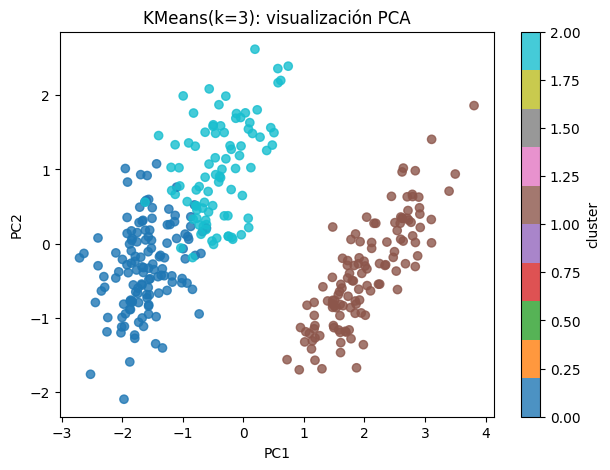

bill_length_mm              bill_depth_mm               \
                median   mean count        median   mean count   
cluster                                                          
0                38.15  38.21   132         18.05  18.11   132   
1                47.30  47.50   123         15.00  14.98   123   
2                47.00  47.53    87         18.80  18.76    87   

        flipper_length_mm               body_mass_g                 
                   median    mean count      median     mean count  
cluster                                                             
0                   189.0  188.40   132      3550.0  3584.66   132  
1                   216.0  217.19   123      5000.0  5076.02   123  
2                   197.0  196.90    87      3900.0  3902.01    87

species,Adelie,Chinstrap,Gentoo
cluster,,,
0,0.96,0.04,0.00
1,0.00,0.00,1.00
2,0.28,0.71,0.01


In [7]:
NOMBRE_ELEGIDO = 'KMeans(k=3)'
pipeline, labels, X_preparado = ajustes[NOMBRE_ELEGIDO]

pca = PCA(n_components=2, random_state=RANDOM_STATE)
coordenadas = pca.fit_transform(X_preparado)
print('Varianza explicada por PC1 y PC2:', np.round(pca.explained_variance_ratio_, 3))

plt.figure(figsize=(7, 5))
plt.scatter(coordenadas[:, 0], coordenadas[:, 1], c=labels, cmap='tab10', alpha=0.8)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'{NOMBRE_ELEGIDO}: visualización PCA')
plt.colorbar(label='cluster')
plt.show()

con_clusters = penguins.assign(cluster=labels)
perfiles = con_clusters.groupby('cluster')[FEATURES].agg(['median', 'mean', 'count'])
display(perfiles.round(2))

tabla_externa = pd.crosstab(con_clusters['cluster'], con_clusters['species'], normalize='index')
display(tabla_externa.round(2))

## Conclusiones

1. Comparar métricas no reemplaza revisar tamaños, perfiles, ruido y estabilidad.
2. La tabla con `species` es un contraste posterior: no convierte el agrupamiento en clasificación.
3. Una solución defendible debe describir representación, parámetros, métricas y límites.